conversion of .tiff into jpeg


In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
from PIL import Image
import os

# Directory containing TIFF images
source_dir = "/content/drive/My Drive/disease1/slices"
# Directory to save JPEG images
target_dir = "/content/drive/My Drive/disease1/slicesjpeg1"

# Check if the target directory exists, if not, create it
if not os.path.exists(target_dir):
    os.makedirs(target_dir)

# Iterate through all files in the source directory
for filename in os.listdir(source_dir):
    if filename.lower().endswith('.tiff') or filename.lower().endswith('.tif'):
        # Path to the current TIFF file
        tiff_path = os.path.join(source_dir, filename)
        # Convert TIFF to JPEG
        with Image.open(tiff_path) as img:
            # Remove the file extension and add ".jpg"
            jpeg_path = os.path.join(target_dir, os.path.splitext(filename)[0] + '.jpg')
            # Convert the image to RGB and save it as a JPEG
            img.convert('RGB').save(jpeg_path, "JPEG")

print("Conversion from TIFF to JPEG is complete.")


Conversion from TIFF to JPEG is complete.


data augmentation

In [ ]:
from keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
import os
from PIL import Image

# Set the path to your dataset
dataset_path = '/content/drive/My Drive/disease1/slicesjpeg1'

# Create an ImageDataGenerator for data augmentation
datagen = ImageDataGenerator(
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Get the list of all image files in the directory
image_files = [os.path.join(dataset_path, filename) for filename in os.listdir(dataset_path) if filename.lower().endswith('.jpg')]

# Iterate through each image in the directory
for image_file in image_files:
    # Load the image
    img = load_img(image_file)

    # Convert the image to a Numpy array
    x = img_to_array(img)

    # Reshape the array to (1, height, width, channels)
    x = x.reshape((1,) + x.shape)

    # Generate augmented images and save them to the specified directory
    i = 0
    for batch in datagen.flow(x, batch_size=1, save_to_dir=dataset_path, save_prefix='aug', save_format='jpg'):
        i += 1
        if i > 20:  # Generate 20 augmented images for each original image
            break

print("Data augmentation complete.")

Data augmentation complete.


In [ ]:
import os

# Set the path to your dataset
dataset_path = '/content/drive/My Drive/disease1/slicesjpeg1'

# List all files in the directory with .tiff or .jpeg extension
image_files = [filename for filename in os.listdir(dataset_path) if filename.endswith(('.jpg'))]

# Get the number of images
num_images = len(image_files)

# Print the result
print(f'The number of images in the directory is: {num_images}')

The number of images in the directory is: 5201


In [ ]:
import os
import cv2
import numpy as np
from sklearn.cluster import KMeans

# Function to extract features from an image (e.g., using color histograms)
def extract_features(image_path):
    img = cv2.imread(image_path)
    if img is None:
        print(f"Error reading image: {image_path}")
        return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert to RGB
    hist_r = cv2.calcHist([img], [0], None, [256], [0, 256])
    hist_g = cv2.calcHist([img], [1], None, [256], [0, 256])
    hist_b = cv2.calcHist([img], [2], None, [256], [0, 256])
    features = np.concatenate((hist_r, hist_g, hist_b)).flatten()
    if np.isnan(features).any():
        print(f"Error extracting features from image: {image_path}")
        return None
    return features

# Directory containing images
dataset_directory ="/content/drive/My Drive/disease1/slicesjpeg1"

# Extract features from all images
image_paths = []
features = []
for root, dirs, files in os.walk(dataset_directory):
    for file in files:
        if file.endswith('.jpg') or file.endswith('.jpg'):
            image_path = os.path.join(root, file)
            image_paths.append(image_path)
            feature = extract_features(image_path)
            if feature is not None:
                features.append(feature)

# Check if features were extracted
if not features:
    print("No features were extracted from the images.")
else:
    features = np.array(features)

    # Perform K-Means clustering
    num_clusters = 4  # Number of categories (NT, PLE, CLE, PSE)
    kmeans = KMeans(n_clusters=num_clusters, random_state=42)
    kmeans.fit(features)

    # Assign cluster labels to images
    cluster_labels = kmeans.labels_

    # Print cluster labels for each image
    for image_path, cluster_label in zip(image_paths, cluster_labels):
        print(f"Image: {image_path}, Cluster Label: {cluster_label}")


/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


Streaming output truncated to the last 5000 lines.
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject84_bottom.jpg, Cluster Label: 0
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject99_bottom.jpg, Cluster Label: 0
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject86_bottom.jpg, Cluster Label: 0
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject89_bottom.jpg, Cluster Label: 0
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject85_bottom.jpg, Cluster Label: 0
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject98_bottom.jpg, Cluster Label: 0
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject108_middle.jpg, Cluster Label: 0
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject107_middle.jpg, Cluster Label: 0
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject106_middle.jpg, Cluster Label: 0
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject108_bottom.jpg, Cluster Label: 0
Image: /content/drive/My Drive/dise

In [ ]:
# Modify this function to assign category names based on visual inspection of images within each cluster
def assign_category(cluster_label):
    # Assign category names based on visual inspection of images within each cluster
    # You may need to manually inspect images within each cluster and assign category names accordingly
    # This is a subjective process and requires domain knowledge or manual inspection
    if cluster_label == 0:
        return 'NT'
    elif cluster_label == 1:
        return 'PLE'
    elif cluster_label == 2:
        return 'PSE'
    elif cluster_label == 3:
        return 'CLE'
    else:
        return 'Unknown'

# Print cluster labels and corresponding category names for each image
for image_path, cluster_label in zip(image_paths, cluster_labels):
    category_name = assign_category(cluster_label)
    print(f"Image: {image_path}, Category: {category_name}")


Streaming output truncated to the last 5000 lines.
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject84_bottom.jpg, Category: NT
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject99_bottom.jpg, Category: NT
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject86_bottom.jpg, Category: NT
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject89_bottom.jpg, Category: NT
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject85_bottom.jpg, Category: NT
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject98_bottom.jpg, Category: NT
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject108_middle.jpg, Category: NT
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject107_middle.jpg, Category: NT
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject106_middle.jpg, Category: NT
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject108_bottom.jpg, Category: NT
Image: /content/drive/My Drive/disease1/slicesjpeg1/subject103_middle.jpg, 

Dataset

In [ ]:
import csv

# Define the file path for saving the dataset
output_file = "/content/drive/My Drive/disease1/image_cluster_labels1.csv"  # Adjust the file path as needed

# Open the CSV file in write mode and create a CSV writer object
with open(output_file, mode='w', newline='') as file:
    writer = csv.writer(file)

    # Write the header row
    writer.writerow(['Image Path', 'Cluster Label', 'Category'])

    # Write the data rows
    for image_path, cluster_label in zip(image_paths, cluster_labels):
        category_name = assign_category(cluster_label)
        writer.writerow([image_path, cluster_label, category_name])

print(f"Dataset saved to: {output_file}")


Dataset saved to: /content/drive/My Drive/disease1/image_cluster_labels1.csv


In [10]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, f1_score
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input
import os

# Load CSV file
csv_path = "/content/drive/My Drive/disease/disease1/image_cluster_labels1.csv"
df = pd.read_csv(csv_path)

# Check for invalid file paths
invalid_paths = df[~df['Image Path'].apply(os.path.exists)]['Image Path']
if not invalid_paths.empty:
    print("Invalid file paths found:")
    print(invalid_paths)
    # Remove rows with invalid file paths
    df = df[df['Image Path'].apply(os.path.exists)]

# Check if 'Image Path' column still exists in DataFrame
if 'Image Path' not in df.columns:
    print("Error: 'Image Path' column does not exist in DataFrame.")
else:
    # Encode class labels for 'Cluster Label'
    label_encoder = LabelEncoder()
    df['classes'] = label_encoder.fit_transform(df['Cluster Label'])
    num_classes = len(label_encoder.classes_)

    # Define image and batch size
    img_size = (224, 224)
    batch_size = 32

    # Create ImageDataGenerator for data augmentation and normalization
    datagen = ImageDataGenerator(
        rescale=1./255,
        shear_range=0.2,
        zoom_range=0.2,
        horizontal_flip=True,
        validation_split=0.2  # Split the data into training and validation sets
    )

    # Create data generators for training, validation, and test
    train_generator = datagen.flow_from_dataframe(
        dataframe=df,
        x_col='Image Path',
        y_col='Cluster Label',
        target_size=img_size,
        batch_size=batch_size,
        subset='training',
        class_mode='raw',  # Use 'raw' for regression tasks
    )

    valid_generator = datagen.flow_from_dataframe(
        dataframe=df,
        x_col='Image Path',
        y_col='Cluster Label',
        target_size=img_size,
        batch_size=batch_size,
        subset='validation',
        class_mode='raw',  # Use 'raw' for regression tasks
    )

    # Build DenseNet121 model
    base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    model = models.Sequential()
    model.add(base_model)
    model.add(layers.Flatten())
    model.add(layers.Dense(512, activation='relu'))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(num_classes, activation='softmax'))

    # Compile the model
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    # Train the model
    history = model.fit(
        train_generator,
        validation_data=valid_generator,
        epochs=5
    )

    # Evaluate the model on the test set
    test_datagen = ImageDataGenerator(rescale=1./255)
    test_generator = test_datagen.flow_from_dataframe(
        dataframe=df,
        x_col='Image Path',
        y_col='Cluster Label',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='raw',
        shuffle=False
    )

    # Predictions
    y_pred = model.predict(test_generator)
    y_pred_cluster_classes = np.argmax(y_pred, axis=1)

    # Obtain true labels for evaluation
    true_labels = label_encoder.transform(test_generator.labels)

    # Calculate F1 score for cluster label
    f1_cluster = f1_score(true_labels, y_pred_cluster_classes, average='weighted')
    print(f'Weighted F1 score for Cluster Label: {f1_cluster}')

    # Classification Report for cluster label
    class_labels_cluster = list(label_encoder.classes_)
    class_labels_cluster_str = [str(label) for label in class_labels_cluster]
    print(classification_report(true_labels, y_pred_cluster_classes, target_names=class_labels_cluster_str))

    # Calculate accuracy, precision, and recall
    report = classification_report(true_labels, y_pred_cluster_classes, target_names=class_labels_cluster_str, output_dict=True)

    accuracy = report['accuracy']
    precision = report['macro avg']['precision']
    recall = report['macro avg']['recall']

    print(f'Accuracy: {accuracy}')
    print(f'Precision: {precision}')
    print(f'Recall: {recall}')


Invalid file paths found:
0       /content/drive/My Drive/disease1/slicesjpeg1/s...
1       /content/drive/My Drive/disease1/slicesjpeg1/s...
2       /content/drive/My Drive/disease1/slicesjpeg1/s...
3       /content/drive/My Drive/disease1/slicesjpeg1/s...
4       /content/drive/My Drive/disease1/slicesjpeg1/s...
                              ...                        
5196    /content/drive/My Drive/disease1/slicesjpeg1/a...
5197    /content/drive/My Drive/disease1/slicesjpeg1/a...
5198    /content/drive/My Drive/disease1/slicesjpeg1/a...
5199    /content/drive/My Drive/disease1/slicesjpeg1/a...
5200    /content/drive/My Drive/disease1/slicesjpeg1/a...
Name: Image Path, Length: 5201, dtype: object


KeyError: 'Image Path'

In [3]:
import os

# Set the path to your dataset
dataset_path = "/content/drive/My Drive/disease/disease1/slicesjpeg1"

# List all files in the directory with .tiff extension
image_files = [filename for filename in os.listdir(dataset_path) if filename.endswith('.jpg')]

# Get the number of images
num_images = len(image_files)

# Print the result
print(f'The number of images in the directory is: {num_images}')


The number of images in the directory is: 5201


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Specify the labels of interest
selected_labels = ['CLE', 'PLE', 'PSE', 'NT']
selected_indices = [label_encoder.transform([label])[0] for label in selected_labels]

# Filter the true and predicted labels for the specified classes
filtered_true_labels = [label for label in true_labels if label in selected_indices]
filtered_pred_labels = [pred for true, pred in zip(true_labels, y_pred_cluster_classes) if true in selected_indices]

# Generate confusion matrix
cm = confusion_matrix(filtered_true_labels, filtered_pred_labels, labels=selected_indices)

# Plot confusion matrix
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=selected_labels, yticklabels=selected_labels)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for Selected Classes')
plt.show()


NameError: name 'label_encoder' is not defined

In [31]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, f1_score
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input
import os

# Load CSV file
csv_path = "/content/drive/My Drive/disease1/image_cluster_labels1.csv"
df = pd.read_csv(csv_path)

# Check for invalid file paths
invalid_paths = df[~df['Image Path'].apply(os.path.exists)]['Image Path']
if not invalid_paths.empty:
    print("Invalid file paths found:")
    print(invalid_paths)
    # Remove rows with invalid file paths
    df = df[~df['Image Path'].apply(lambda x: not os.path.exists(x))]

# Check if 'Image Path' column still exists in DataFrame
if 'Image Path' not in df.columns:
    print("Error: 'Image Path' column does not exist in DataFrame.")
else:
    # Encode class labels for 'Cluster Label'
    label_encoder = LabelEncoder()
    df['classes'] = label_encoder.fit_transform(df['Cluster Label'])
    num_classes = len(label_encoder.classes_)

    # Define image and batch size
    img_size = (224, 224)
    batch_size = 32

    # Create ImageDataGenerator for data augmentation and normalization
    datagen = ImageDataGenerator(
        rescale=1./255,
        shear_range=0.2,
        zoom_range=0.2,
        horizontal_flip=True,
        validation_split=0.2  # Split the data into training and validation sets
    )

    # Create data generators for training, validation, and test
    train_generator = datagen.flow_from_dataframe(
        dataframe=df,
        x_col='Image Path',
        y_col='Cluster Label',
        target_size=img_size,
        batch_size=batch_size,
        subset='training',
        class_mode='raw',  # Use 'raw' for regression tasks
    )

    valid_generator = datagen.flow_from_dataframe(
        dataframe=df,
        x_col='Image Path',
        y_col='Cluster Label',
        target_size=img_size,
        batch_size=batch_size,
        subset='validation',
        class_mode='raw',  # Use 'raw' for regression tasks
    )

    # Build DenseNet121 model
    base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
    base_model.trainable = False

    model = models.Sequential()
    model.add(base_model)
    model.add(layers.Flatten())
    model.add(layers.Dense(512, activation='relu'))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(num_classes, activation='softmax'))

    # Compile the model
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

    # Train the model
    history = model.fit(
        train_generator,
        validation_data=valid_generator,
        epochs=5
    )

    # Evaluate the model on the test set
    test_datagen = ImageDataGenerator(rescale=1./255)
    test_generator = test_datagen.flow_from_dataframe(
        dataframe=df,
        x_col='Image Path',
        y_col='Cluster Label',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='raw',
        shuffle=False
    )

    # Predictions
    y_pred = model.predict(test_generator)
    y_pred_cluster_classes = np.argmax(y_pred, axis=1)

    # Obtain true labels for evaluation
    true_labels = label_encoder.transform(test_generator.labels)

    # Calculate F1 score for cluster label
    f1_cluster = f1_score(true_labels, y_pred_cluster_classes, average='weighted')
    print(f'Weighted F1 score for Cluster Label: {f1_cluster}')

    # Classification Report for cluster label
    class_labels_cluster = list(label_encoder.classes_)
    class_labels_cluster_str = [str(label) for label in class_labels_cluster]
    print(classification_report(true_labels, y_pred_cluster_classes, target_names=class_labels_cluster_str))

    # Calculate accuracy, precision, and recall
    report = classification_report(true_labels, y_pred_cluster_classes, target_names=class_labels_cluster_str, output_dict=True)

    accuracy = report['accuracy']
    precision = report['macro avg']['precision']
    recall = report['macro avg']['recall']

    print(f'Accuracy: {accuracy}')
    print(f'Precision: {precision}')
    print(f'Recall: {recall}')


Found 4161 validated image filenames.
Found 1040 validated image filenames.
Epoch 1/5
131/131 [==============================] - 1828s 14s/step - loss: 0.4283 - accuracy: 0.9156 - val_loss: 0.0152 - val_accuracy: 0.9933
Epoch 2/5
131/131 [==============================] - 1270s 10s/step - loss: 0.0557 - accuracy: 0.9837 - val_loss: 0.0045 - val_accuracy: 0.9990
Epoch 3/5
131/131 [==============================] - 1263s 10s/step - loss: 0.0447 - accuracy: 0.9849 - val_loss: 0.0044 - val_accuracy: 0.9990
Epoch 4/5
131/131 [==============================] - 1241s 9s/step - loss: 0.0269 - accuracy: 0.9916 - val_loss: 0.0026 - val_accuracy: 0.9990
Epoch 5/5
131/131 [==============================] - 1254s 10s/step - loss: 0.0266 - accuracy: 0.9933 - val_loss: 0.0016 - val_accuracy: 1.0000
Found 5201 validated image filenames.
163/163 [==============================] - 1115s 7s/step
Weighted F1 score for Cluster Label: 0.9984808921215181
              precision    recall  f1-score   support


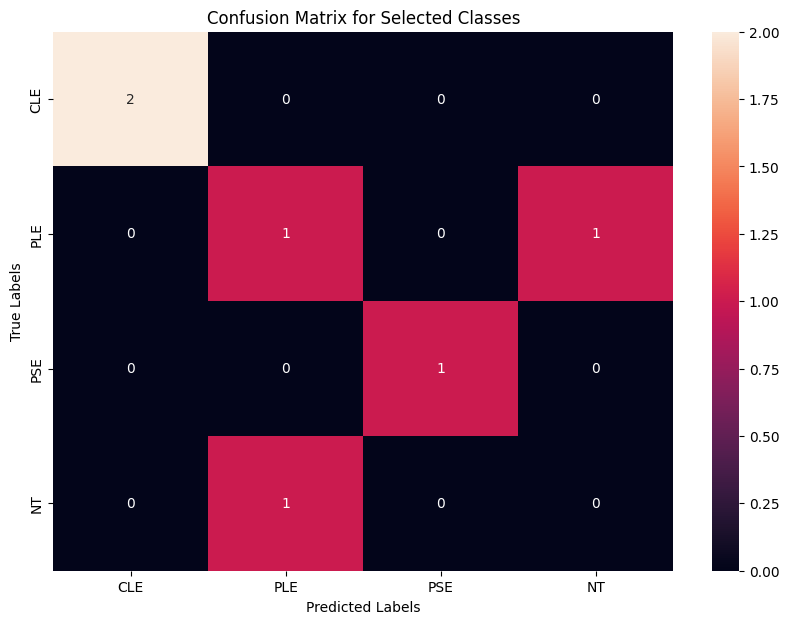

In [33]:
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Example data
true_labels = ['CLE', 'PLE', 'CLE', 'PSE', 'NT', 'PLE']
y_pred_cluster_classes = ['CLE', 'PLE', 'CLE', 'PSE', 'PLE', 'NT']

# Specify the labels of interest
selected_labels = ['CLE', 'PLE', 'PSE', 'NT']
label_encoder = LabelEncoder()
label_encoder.fit(selected_labels)  # Fit on the selected labels

# Transform selected labels to indices
selected_indices = [label_encoder.transform([label])[0] for label in selected_labels]

# Filter true and predicted labels
filtered_true_labels = [label for label in true_labels if label in selected_labels]
filtered_pred_labels = [pred for true, pred in zip(true_labels, y_pred_cluster_classes) if true in selected_labels]

# Convert labels to encoded indices for the confusion matrix
filtered_true_indices = [label_encoder.transform([label])[0] for label in filtered_true_labels]
filtered_pred_indices = [label_encoder.transform([label])[0] for label in filtered_pred_labels]

# Generate confusion matrix
cm = confusion_matrix(filtered_true_indices, filtered_pred_indices, labels=selected_indices)

# Plot confusion matrix
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=selected_labels, yticklabels=selected_labels)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix for Selected Classes')
plt.show()
